In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate 2-Feature Synthetic Dataset
X, y = make_classification(
    n_samples=1000,
    n_features=2,        # Only 2 features (e.g., Feature1, Feature2)
    n_informative=2,    # Both features carry useful signal
    n_redundant=0,
    n_clusters_per_class=1,
    n_classes=2,
    random_state=42
)

# 2. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Standardize Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Convert to TensorFlow Dataset objects
batch_size = 32
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(1000).batch(batch_size)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

# Verification
print(f"X_train shape: {X_train.shape}")  # Outputs: (800, 2)
print(f"y_train shape: {y_train.shape}")  # Outputs: (800,)

X_train shape: (800, 2)
y_train shape: (800,)


### Xavier Technique(For Tanh or sometime Sigmoid)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

In [ ]:
model = Sequential()

adam = Adam(learning_rate=0.01)

model.add(Dense(units = 128 , activation = 'tanh' ,kernel_initializer = 'glorot_normal' , input_dim = 2))
model.add(Dense(units = 64 , activation = 'tanh' , kernel_initializer = 'glorot_normal'))
model.add(Dense(units = 1 , activation = 'sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,705 (34.00 KB)

 Trainable params: 8,705 (34.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer = adam , loss = 'binary_crossentropy' , metrics = ['accuracy'])

In [ ]:
history = model.fit(x =  X_train , y = y_train , validation_data = (X_test , y_test) , epochs =  100)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8612 - loss: 0.3663 - val_accuracy: 0.9100 - val_loss: 0.2774
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9087 - loss: 0.2204 - val_accuracy: 0.8750 - val_loss: 0.2363
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9050 - loss: 0.1932 - val_accuracy: 0.8400 - val_loss: 0.2170
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9038 - loss: 0.1740 - val_accuracy: 0.8600 - val_loss: 0.1977
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9162 - loss: 0.1596 - val_accuracy: 0.8900 - val_loss: 0.1800
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9300 - loss: 0.1463 - val_accuracy: 0.9400 - val_loss: 0.1669
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9425 - loss: 0.1394 - val_accuracy: 0.9450 - val_loss: 0.1642
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9388 - loss: 0.1389 - val_accuracy: 0.9400 -

In [ ]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step


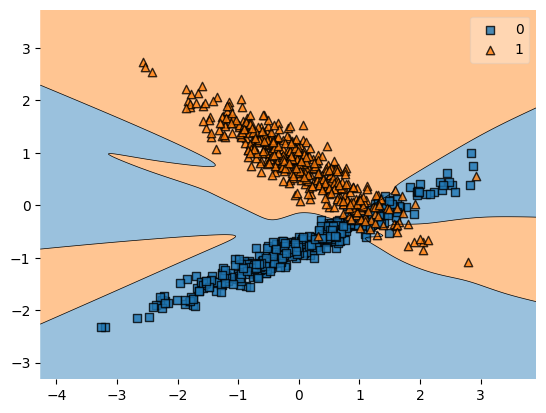

In [ ]:
plot_decision_regions(X_train, y_train, clf=model)
plt.show()

He Technique(For ReLu)

In [ ]:
model1 = Sequential()

adam1 = Adam(learning_rate=0.01)

model1.add(Dense(units = 128 , activation = 'tanh' ,kernel_initializer = 'he_normal' , input_dim = 2))
model1.add(Dense(units = 64 , activation = 'tanh' , kernel_initializer = 'he_normal'))
model1.add(Dense(units = 1 , activation = 'sigmoid'))

model1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,705 (34.00 KB)

 Trainable params: 8,705 (34.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model1.compile(optimizer = adam1 , loss = 'binary_crossentropy' , metrics = ['accuracy'])

In [ ]:
history1 = model1.fit(x =  X_train , y = y_train , validation_data = (X_test , y_test) , epochs =  100)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8888 - loss: 0.2348 - val_accuracy: 0.8950 - val_loss: 0.2139
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9125 - loss: 0.1830 - val_accuracy: 0.9150 - val_loss: 0.1925
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9125 - loss: 0.1636 - val_accuracy: 0.8950 - val_loss: 0.1901
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9262 - loss: 0.1542 - val_accuracy: 0.9200 - val_loss: 0.1817
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9312 - loss: 0.1464 - val_accuracy: 0.9100 - val_loss: 0.1825
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9325 - loss: 0.1424 - val_accuracy: 0.9150 - val_loss: 0.1814
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9325 - loss: 0.1396 - val_accuracy: 0.9150 - val_loss: 0.1779
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9325 - loss: 0.1380 - val_accuracy: 0.9250 - 

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


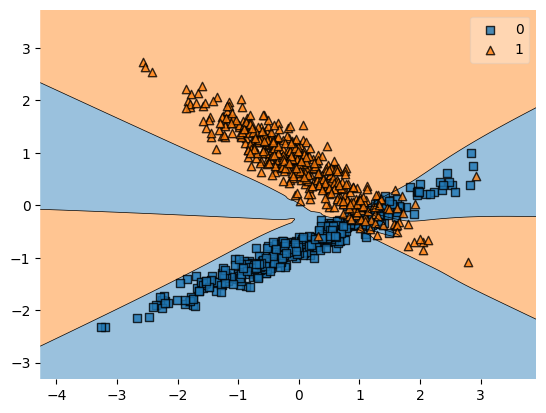

In [ ]:
plot_decision_regions(X_train, y_train, clf=model1)
plt.show()